# ColorMNIST: DoubleGen-style nuisance-corruption pilot

This notebook reads the completed seed-0 pilot; it runs no simulation. The four cells cross the usual fitted CME with a CME trained only on $X<0.5$, and baseline inverse weights with weights multiplied by $1/4$ for $X\geq0.5$. **Baseline fitted nuisances are not oracle nuisances.**

The protocol adapts [DoubleGen, Appendix M.1.1 and Table 3](https://arxiv.org/html/2509.16842v1#A13.SS1.SSS1), rather than reproducing its generative model or CelebA experiment. See the [experiment protocol](README.md) and [bibliography](references.bib) for assumptions, controls, and classical DR references.

Results below are equal averages over the two intervention arms **within one data seed**. There is no across-seed standard deviation or confidence interval. This pilot can reveal a mechanism or implementation problem; it cannot establish reproducible robustness.

In [1]:
from pathlib import Path
from itertools import product
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

RUN_DIR = Path("results/doublegen_raw_pilot_seed0")
provenance = json.loads((RUN_DIR / "provenance.json").read_text())
assert provenance["status"] == "complete", "The pilot has not completed; do not analyse partial output."
config = provenance["config"]
results = pd.read_csv(RUN_DIR / "results.csv")

cell_order = list(product(["full", "blue_only"], ["baseline", "red_downweighted"]))
estimator_order = ["plugin", "ipw", "dr"]
keys = ["data_seed", "arm", "cme_mode", "weight_mode", "estimator"]
expected = set(product([0], [0, 1], ["full", "blue_only"],
                       ["baseline", "red_downweighted"], estimator_order))
actual = set(results[keys].itertuples(index=False, name=None))
assert not results.duplicated(keys).any(), "Duplicate result keys."
assert actual == expected and len(results) == 24, "Missing or unexpected experiment cells."
assert provenance["rows"] == len(results)
assert provenance["data_seed"] == 0 and config["arms"] == [0, 1]
assert config["corruption_mass"] == "raw" and not config["targets_only"]
assert results["corruption_mass"].eq("raw").all()
for name in ["n_obs", "n_ae", "n_particles", "n_ref", "dr_fit", "threshold", "downweight"]:
    assert results[name].eq(config[name]).all(), f"Configuration mismatch: {name}"

metrics = ["target_rbf_squared_distance", "pixel_sw2_flow", "colour_w1_uniform_flow"]
mass_metrics = ["sum_v", "sum_abs_v", "negative_mass", "target_colour_mean",
                "target_colour_mean_divided_by_mass"]
assert np.isfinite(results[metrics + mass_metrics].to_numpy()).all()
assert (results[metrics].to_numpy() >= -1e-10).all()
assert results.groupby("shared_flow_id")[metrics + mass_metrics].nunique().le(1).all().all()

display(pd.Series({
    "data seed": provenance["data_seed"],
    "logged observations": config["n_obs"],
    "independent AE observations": config["n_ae"],
    "particles / reference images": f'{config["n_particles"]} / {config["n_ref"]}',
    "nuisance fit / folds": f'{config["dr_fit"]} / {config["n_folds"]}',
    "landmark budget": config["n_landmarks"],
    "AE / flow iterations": f'{config["ae_iterations"]} / {config["flow_iterations"]}',
    "SW2 projections": config["n_projections"],
    "corruption mass mode": config["corruption_mass"],
    "configuration rows / unique flows": f'{len(results)} / {results["shared_flow_id"].nunique()}',
    "saved runtime, minutes": round(provenance["seconds_total"] / 60, 2),
}, name="Completed pilot"))

data seed                                       0
logged observations                          5000
independent AE observations                  5000
particles / reference images          1000 / 1000
nuisance fit / folds                 crossfit / 2
landmark budget                               512
AE / flow iterations                  3000 / 3000
SW2 projections                              1000
corruption mass mode                          raw
configuration rows / unique flows         24 / 16
saved runtime, minutes                        4.6
Name: Completed pilot, dtype: object

## Target accuracy and final samples

Target error is the squared **latent RBF RKHS distance** between the raw fitted target embedding and an independent oracle empirical embedding. It includes total-mass error and reference Monte Carlo error; it is distinct from the IMQ objective optimized by the flow. Pixel SW2 compares decoded particles with matched-count oracle images. Colour W1 compares their empirical foreground-red fractions directly with the exact Uniform$[0,1]$ target. Lower is better.

Each table displays the full $2\times2$ nuisance design. Plug-in does not use inverse weights, and IPW does not use a CME: their repeated rows reuse the same target and flow. These are shared controls, not additional repetitions.

In [2]:
group_keys = ["data_seed", "cme_mode", "weight_mode", "estimator"]
arm_counts = results.groupby(group_keys)["arm"].nunique()
assert arm_counts.eq(2).all(), "Every reported mean must include both intervention arms."
within_seed = results.groupby(group_keys, sort=False)[metrics + mass_metrics].mean()
means = within_seed.xs(0, level="data_seed")

cme_labels = {"full": "Baseline CME", "blue_only": "Blue-only CME"}
weight_labels = {"baseline": "Baseline weights", "red_downweighted": "Red weights × 1/4"}
estimator_labels = {"plugin": "Plug-in", "ipw": "IPW", "dr": "DR"}
metric_labels = {
    "target_rbf_squared_distance": "Target RBF squared error",
    "pixel_sw2_flow": "Final pixel SW2",
    "colour_w1_uniform_flow": "Final colour W1 to Uniform[0,1]",
}

def metric_table(metric):
    table = means[metric].unstack("estimator").reindex(
        pd.MultiIndex.from_tuples(cell_order, names=["cme_mode", "weight_mode"])
    )[estimator_order]
    table.index = pd.MultiIndex.from_tuples(
        [(cme_labels[cme], weight_labels[weight]) for cme, weight in cell_order],
        names=["CME fit", "Inverse weights"],
    )
    return table.rename(columns=estimator_labels)

for metric in metrics:
    display(Markdown(f"**{metric_labels[metric]} — mean over arms, seed 0**"))
    display(metric_table(metric).style.format("{:.6f}"))

**Target RBF squared error — mean over arms, seed 0**

**Final pixel SW2 — mean over arms, seed 0**

**Final colour W1 to Uniform[0,1] — mean over arms, seed 0**

## Shared controls and coefficient mass

Controls use the actual decoded initial particles, an independent count-matched oracle sample, and that oracle sample after an encoder–decoder round trip. Oracle-sample scores are comparison levels, not lower bounds. The oracle–oracle RBF comparison uses two reference samples of size n_ref; the fitted target uses n_obs logged observations and estimated nuisances. Their different construction and sample sizes prevent interpreting the oracle comparison as a matched estimator floor.

Raw inverse-weight corruption changes both mass and shape. With ideal nuisances its expected IPW mass is $0.625$; after unit-mass rescaling its colour mean would be $0.35$, rather than the intended $0.5$. No fitted target is renormalized here. The separate mass-preserving corruption experiment is not included in this pilot. A signed DR expansion need not define a probability law: its raw first moment and first moment divided by mass are diagnostics only.

In [3]:
control_columns = [
    f"{metric}_{stage}"
    for stage in ["initial", "floor", "roundtrip_floor"]
    for metric in ["pixel_sw2", "colour_w1_uniform"]
] + ["target_rbf_oracle_floor"]
weight_columns = ["sum_w_baseline", "sum_w_corrupted", "ess_w_baseline", "ess_w_corrupted"]
assert results.groupby(["data_seed", "arm"])[control_columns + weight_columns].nunique().le(1).all().all()
per_arm_controls = results.drop_duplicates(["data_seed", "arm"]).set_index("arm")
controls = per_arm_controls[control_columns].mean()
control_table = pd.DataFrame([
    {"Control": label, "Pixel SW2": controls[f"pixel_sw2_{stage}"],
     "Colour W1 to Uniform[0,1]": controls[f"colour_w1_uniform_{stage}"]}
    for stage, label in [
        ("initial", "Decoded initialization"),
        ("floor", "Independent oracle sample"),
        ("roundtrip_floor", "Oracle decoder round trip"),
    ]
]).set_index("Control")
display(control_table.style.format("{:.6f}"))
display(Markdown(f'**Oracle–oracle target RBF squared distance:** {controls["target_rbf_oracle_floor"]:.6f} (arm mean).'))

weight_table = per_arm_controls[weight_columns].copy()
weight_table["sum_w_baseline"] /= config["n_obs"]
weight_table["sum_w_corrupted"] /= config["n_obs"]
weight_table = weight_table.rename(columns={
    "sum_w_baseline": "Baseline IPW mass", "sum_w_corrupted": "Corrupted IPW mass",
    "ess_w_baseline": "Baseline weight ESS", "ess_w_corrupted": "Corrupted weight ESS",
})
display(Markdown("**Inverse-weight diagnostics by arm**"))
display(weight_table.style.format("{:.4f}"))

mass_table = means[mass_metrics].reindex(
    pd.MultiIndex.from_tuples(
        [(cme, weight, est) for cme, weight in cell_order for est in estimator_order],
        names=["cme_mode", "weight_mode", "estimator"],
    )
).rename(index={**cme_labels, **weight_labels, **estimator_labels}).rename(columns={
    "sum_v": "Target mass", "sum_abs_v": "Absolute mass", "negative_mass": "Negative mass",
    "target_colour_mean": "Raw colour first moment",
    "target_colour_mean_divided_by_mass": "First moment / mass",
})
display(Markdown("**Target diagnostics — mean over arms, seed 0**"))
display(mass_table.style.format("{:.5f}"))

,Pixel SW2,"Colour W1 to Uniform[0,1]"
Control,,
Decoded initialization,0.043337,0.215453
Independent oracle sample,0.008964,0.013340
Oracle decoder round trip,0.010833,0.018807


**Oracle–oracle target RBF squared distance:** 0.000783 (arm mean).

**Inverse-weight diagnostics by arm**

,Baseline IPW mass,Corrupted IPW mass,Baseline weight ESS,Corrupted weight ESS
arm,,,,
0,0.9724,0.6247,422.7367,1539.7489
1,0.9948,0.6259,316.7648,130.1030


**Target diagnostics — mean over arms, seed 0**

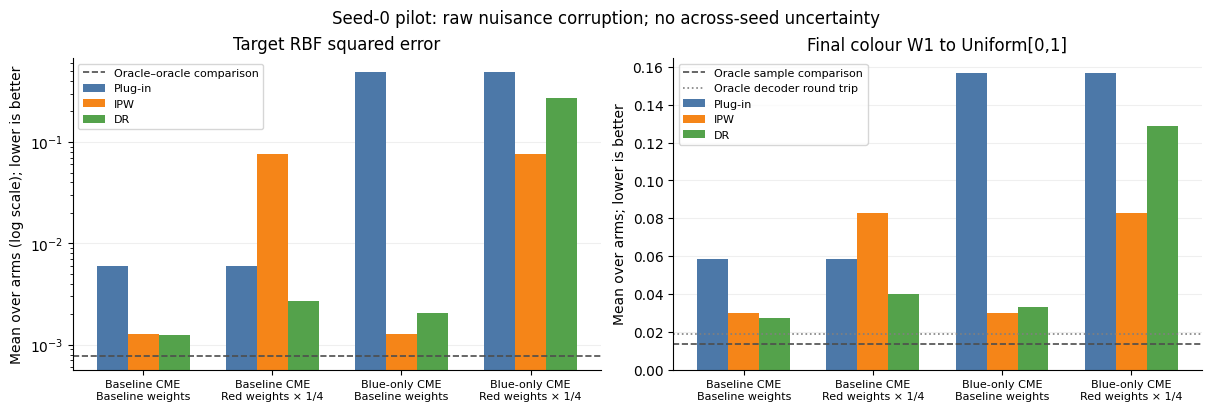

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
positions = np.arange(len(cell_order))
width = 0.24
colours = ["#4c78a8", "#f58518", "#54a24b"]
for ax, metric in zip(axes, [metrics[0], metrics[2]]):
    table = metric_table(metric)
    for j, (estimator, colour) in enumerate(zip(estimator_order, colours)):
        ax.bar(positions + (j - 1) * width, table[estimator_labels[estimator]],
               width=width, label=estimator_labels[estimator], color=colour)
    ax.set_xticks(positions, [
        "Baseline CME\nBaseline weights",
        "Baseline CME\nRed weights × 1/4",
        "Blue-only CME\nBaseline weights",
        "Blue-only CME\nRed weights × 1/4",
    ], fontsize=8)
    ax.set_title(metric_labels[metric])
    if metric == "target_rbf_squared_distance":
        assert (table.to_numpy() > 0).all(), "Log scale requires strictly positive target errors."
        ax.set_yscale("log")
        ax.set_ylabel("Mean over arms (log scale); lower is better")
    else:
        ax.set_ylabel("Mean over arms; lower is better")
        ax.set_ylim(bottom=0)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
axes[0].axhline(controls["target_rbf_oracle_floor"], color="0.3", linestyle="--",
               linewidth=1.2, label="Oracle–oracle comparison")
axes[1].axhline(controls["colour_w1_uniform_floor"], color="0.3", linestyle="--",
               linewidth=1.2, label="Oracle sample comparison")
axes[1].axhline(controls["colour_w1_uniform_roundtrip_floor"], color="0.5", linestyle=":",
               linewidth=1.2, label="Oracle decoder round trip")
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
fig.suptitle("Seed-0 pilot: raw nuisance corruption; no across-seed uncertainty")
fig.savefig(RUN_DIR / "nuisance_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

## Per-arm results and interpretation

Inspect both arms before interpreting their average. A DR advantage in a single-corruption cell is compatible with the proposed mechanism, but finite-sample nuisance error, low effective sample size, total mass, representation error, and finite flow optimization can each affect the comparison. The both-corrupted cell has no generic DR consistency guarantee.

The same fitted representation, data, initialization, oracle references, and metric randomness are shared across cells. Repeated Plug-in/IPW flows must remain paired and must not count as independent observations. A rebuttal result requires new independent data seeds, averaging arms within each seed before estimating across-seed uncertainty.

In [5]:
per_arm = results.sort_values(keys).set_index(
    ["arm", "cme_mode", "weight_mode", "estimator"]
)[metrics + ["sum_v", "negative_mass", "colour_mean_flow"]]
per_arm = per_arm.rename(index={**cme_labels, **weight_labels, **estimator_labels}).rename(
    columns={**metric_labels, "sum_v": "Target mass",
             "negative_mass": "Negative mass", "colour_mean_flow": "Final colour mean"}
)
display(per_arm.style.format("{:.6f}"))